In [ ]:
%pip install -q -U langgraph langchain-groq

In [ ]:
from google.colab import userdata
import os

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

In [ ]:
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from typing import TypedDict

In [ ]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [ ]:
class LLMState(TypedDict):
  question:str
  answer:str

In [ ]:
def QA_chatbot(state:LLMState) -> LLMState:
  question = state['question']
  # Prompt
  prompt = f'Give answer to the following question {question}'
  answer = model.invoke(prompt).content
  # Update state
  state['answer'] = answer
  return state

In [ ]:
# Define the graph
graph = StateGraph(LLMState)

# Define node
graph.add_node('QA_chatbot',QA_chatbot)

# Define edges
graph.add_edge(START,'QA_chatbot')
graph.add_edge('QA_chatbot',END)

In [ ]:
# Compile the graph
workflow = graph.compile()

In [ ]:
# Execute the graph
initial_state = {'question':'How far is earth from sun?'}
final_state = workflow.invoke(initial_state)
print(final_state['answer'])

The average distance from the Earth to the Sun is about **149.6 million kilometers** (≈ 93 million miles).  
This distance is called an **astronomical unit (AU)**, and because Earth's orbit is slightly elliptical, the distance ranges roughly from 147 million km (perihelion) to 152 million km (aphelion).


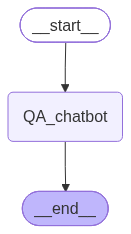

In [ ]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [ ]:
model.invoke('How far is earth from sun?').content

'The average distance from the Earth to the Sun is about **149.6\u202fmillion kilometers** (≈\u202f93\u202fmillion miles).  \nThis is defined as one Astronomical Unit (AU). Because Earth’s orbit is slightly elliptical, the distance varies:\n\n| Point in orbit | Distance (km) | Distance (mi) |\n|----------------|---------------|---------------|\n| Perihelion (closest) | ≈\u202f147\u202fmillion km | ≈\u202f91\u202fmillion mi |\n| Aphelion (farthest) | ≈\u202f152\u202fmillion km | ≈\u202f94\u202fmillion mi |\n\nSo, roughly 150\u202fmillion km on average.'

# THANKS